In [1]:
from pytorchvideo.data.hmdb51 import Hmdb51
from pytorchvideo.data.ucf101 import Ucf101
from pytorchvideo.data.clip_sampling import UniformClipSampler
import os
import pickle

In [7]:
dataset_test = Hmdb51(
    data_path=r"datasets/hmdb/test_train_splits/testTrainMulti_7030_splits",
    clip_sampler=UniformClipSampler(1000),  # sample whole clips
    decode_audio=False,
    video_path_prefix="datasets/hmdb/data",
    split_type="test",
)

In [22]:
from models.vivit_custom.utils.scheduler import WarmupCosineSchedule
import torch
from transformers import ViTForImageClassification

In [23]:
model = ViTForImageClassification.from_pretrained(f"WinKawaks/vit-tiny-patch16-224")

/opt/conda/envs/msc/lib/python3.12/site-packages/huggingface_hub/file_download.py:1132: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


In [24]:
optimizer = torch.optim.SGD(
    model.parameters(), lr=0.001, momentum=0.9, weight_decay=0.0005
)

scheduler = WarmupCosineSchedule(
    optimizer, warmup_steps=110, t_total=1890
)

In [25]:
import matplotlib.pyplot as plt

In [30]:
lrs = []
for step in range(1890):
    lrs.append(scheduler.get_lr()[0])
    scheduler.step()

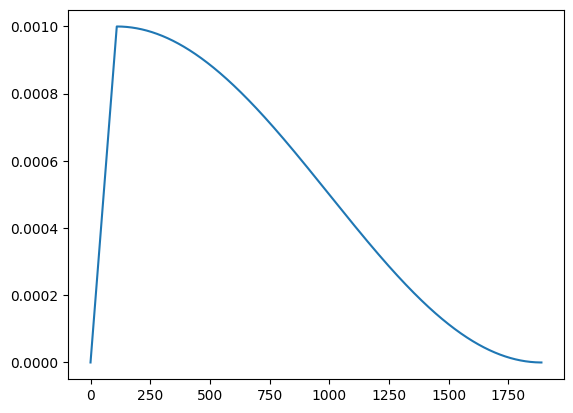

In [27]:
plt.plot(lrs)